# Kinyarwanda Sentiment Classification: Final Model and Hugging Face Upload

Retrains the selected configuration (AfroXLMR-large, learning rate 1e-5, seed 42, five epochs, best epoch kept by validation macro-F1) so that the model survives outside a Colab session, then uploads it to the Hugging Face Hub for the web app. Data, cleaning, loss and training loop are the same as in the fine-tuning notebook.

## Setup

In [1]:
!pip install -q transformers

In [2]:
import re, os, json, random, time, gc
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from datasets import load_dataset
from transformers import AutoTokenizer, AutoModelForSequenceClassification, get_linear_schedule_with_warmup
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

SEED = 42
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", torch.cuda.get_device_name(0) if device.type == "cuda" else "cpu")

Device: Tesla T4


## Data
Mentions are dropped and whitespace is collapsed; case is kept and tweets are truncated at 128 subword tokens.

In [3]:
base = "hf://datasets/shmuhammad/AfriSenti-twitter-sentiment@refs%2Fconvert%2Fparquet/kin"
ds = load_dataset("parquet", data_files={
    "train":      f"{base}/train/0000.parquet",
    "validation": f"{base}/validation/0000.parquet",
    "test":       f"{base}/test/0000.parquet",
})
label_names = ds["train"].features["label"].names

def clean(text):
    return re.sub(r"\s+", " ", re.sub(r"@user", " ", text)).strip()

train_df, val_df, test_df = (ds[s].to_pandas() for s in ("train", "validation", "test"))
for d in (train_df, val_df, test_df):
    d["clean"] = d["tweet"].apply(clean)
y_train, y_val, y_test = (d["label"].tolist() for d in (train_df, val_df, test_df))

HUB_MODEL = "Davlan/afro-xlmr-large"
MAX_LEN = 128
tok = AutoTokenizer.from_pretrained(HUB_MODEL)
enc = lambda texts: tok(list(texts), truncation=True, max_length=MAX_LEN)["input_ids"]
tr, va, te = enc(train_df["clean"]), enc(val_df["clean"]), enc(test_df["clean"])
pad_id = tok.pad_token_id
print(len(tr), len(va), len(te))

kin/train/0000.parquet: reconstructing file:   0%|          |  0.00B /  270kB            

kin/train/0000.parquet: downloading bytes:           |  0.00B            

kin/validation/0000.parquet: reconstructing file:   0%|          |  0.00B / 66.8kB            

kin/validation/0000.parquet: downloading bytes:           |  0.00B            

kin/test/0000.parquet: reconstructing file:   0%|          |  0.00B / 86.3kB            

...

sentencepiece.bpe.model: downloading bytes:           |  0.00B            

tokenizer.json: reconstructing file:   0%|          |  0.00B / 17.1MB            

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

3302 827 1026


## Training
AdamW (weight decay 0.01), linear warm-up over 10% of the steps then linear decay, batch size 16, mixed precision, class-weighted cross-entropy and gradient clipping at 1.0. After each epoch the model is scored on validation; the best epoch is saved to `final_model` together with its test predictions. Weights are cast to fp32 after loading because the large checkpoint is stored in half precision.

In [4]:
LR, BATCH_SIZE, EVAL_BATCH, EPOCHS = 1e-5, 16, 64, 5
WARMUP, WEIGHT_DECAY = 0.1, 0.01
use_amp = device.type == "cuda"

counts = np.bincount(y_train)
class_weights = torch.tensor(len(y_train) / (len(label_names) * counts), dtype=torch.float32).to(device)

def make_batches(ids, labels, batch_size, shuffle):
    order = np.random.permutation(len(ids)) if shuffle else np.arange(len(ids))
    for s in range(0, len(ids), batch_size):
        idx = order[s:s + batch_size]
        seqs = [ids[i] for i in idx]
        width = max(len(q) for q in seqs)
        x = torch.full((len(seqs), width), pad_id, dtype=torch.long)
        mask = torch.zeros((len(seqs), width), dtype=torch.long)
        for j, q in enumerate(seqs):
            x[j, :len(q)] = torch.tensor(q)
            mask[j, :len(q)] = 1
        y = torch.tensor([labels[i] for i in idx])
        yield x.to(device), mask.to(device), y.to(device)

def predict(model, ids, labels):
    model.eval()
    preds = []
    with torch.no_grad(), torch.autocast(device.type, dtype=torch.float16, enabled=use_amp):
        for x, mask, _ in make_batches(ids, labels, EVAL_BATCH, False):
            preds += model(input_ids=x, attention_mask=mask).logits.argmax(-1).tolist()
    return preds

def scores(y_true, y_pred):
    _, _, f1, _ = precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=0)
    return {"accuracy": accuracy_score(y_true, y_pred), "macro_f1": f1}

In [5]:
torch.manual_seed(SEED); np.random.seed(SEED); random.seed(SEED)
model = AutoModelForSequenceClassification.from_pretrained(
    HUB_MODEL, num_labels=len(label_names),
    id2label=dict(enumerate(label_names)),
    label2id={n: i for i, n in enumerate(label_names)}).float().to(device)

optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
total_steps = EPOCHS * ((len(tr) + BATCH_SIZE - 1) // BATCH_SIZE)
scheduler = get_linear_schedule_with_warmup(optimizer, int(WARMUP * total_steps), total_steps)
scaler = torch.amp.GradScaler("cuda", enabled=use_amp)
loss_fn = nn.CrossEntropyLoss(weight=class_weights)

best = {"val_macro_f1": -1}
t0 = time.time()
for epoch in range(1, EPOCHS + 1):
    model.train()
    for x, mask, y in make_batches(tr, y_train, BATCH_SIZE, True):
        optimizer.zero_grad()
        with torch.autocast(device.type, dtype=torch.float16, enabled=use_amp):
            logits = model(input_ids=x, attention_mask=mask).logits
        scaler.scale(loss_fn(logits.float(), y)).backward()
        scaler.unscale_(optimizer)
        nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        scaler.step(optimizer); scaler.update()
        scheduler.step()

    val_f1 = scores(y_val, predict(model, va, y_val))["macro_f1"]
    print(f"epoch {epoch}: val macro-F1 {val_f1:.3f}  ({(time.time() - t0) / 60:.1f} min)")
    if val_f1 > best["val_macro_f1"]:
        test_preds = predict(model, te, y_test)
        test = scores(y_test, test_preds)
        best = {"val_macro_f1": val_f1, "best_epoch": epoch, "test_macro_f1": test["macro_f1"],
                "test_accuracy": test["accuracy"], "test_preds": test_preds}
        model.save_pretrained("final_model")
        tok.save_pretrained("final_model")

print(f"\nBest epoch {best['best_epoch']}: val F1 {best['val_macro_f1']:.3f} | "
      f"test F1 {best['test_macro_f1']:.3f} | test accuracy {best['test_accuracy']:.3f}")

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.12GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/389 [00:00<?, ?it/s]

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: Davlan/afro-xlmr-large
Key                        | Status     | 
---------------------------+------------+-
lm_head.layer_norm.weight  | UNEXPECTED | 
lm_head.dense.weight       | UNEXPECTED | 
lm_head.dense.bias         | UNEXPECTED | 
lm_head.layer_norm.bias    | UNEXPECTED | 
lm_head.bias               | UNEXPECTED | 
classifier.dense.bias      | MISSING    | 
classifier.out_proj.weight | MISSING    | 
classifier.out_proj.bias   | MISSING    | 
classifier.dense.weight    | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
/tmp/ipykernel_4989/3805530122.py:25: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order

epoch 1: val macro-F1 0.642  (1.5 min)


...

epoch 2: val macro-F1 0.689  (3.9 min)


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

epoch 3: val macro-F1 0.693  (7.4 min)


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

epoch 4: val macro-F1 0.689  (11.6 min)
epoch 5: val macro-F1 0.682  (13.0 min)

Best epoch 3: val F1 0.693 | test F1 0.697 | test accuracy 0.693


## Evaluation of the deployed model
Per-class precision, recall and F1 and the confusion matrix for the model that is uploaded. These are the numbers to quote in the report, together with the three-seed means from the experiment notebook.

              precision    recall  f1-score   support

    positive      0.689     0.799     0.740       278
     neutral      0.662     0.644     0.653       393
    negative      0.733     0.665     0.697       355

    accuracy                          0.693      1026
   macro avg      0.695     0.702     0.697      1026
weighted avg      0.694     0.693     0.692      1026



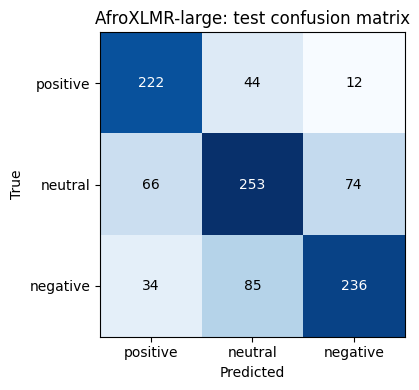

Saved final_metrics.json, final_confusion_matrix.png, test_predictions_final.csv


In [6]:
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix, precision_recall_fscore_support

y_pred = best["test_preds"]
print(classification_report(y_test, y_pred, target_names=label_names, digits=3))

p, r, f, s = precision_recall_fscore_support(y_test, y_pred, zero_division=0)
per_class = {n: {"precision": float(p[i]), "recall": float(r[i]), "f1": float(f[i]), "support": int(s[i])}
             for i, n in enumerate(label_names)}
mp, mr, mf, _ = precision_recall_fscore_support(y_test, y_pred, average="macro", zero_division=0)

cm = confusion_matrix(y_test, y_pred)
fig, ax = plt.subplots(figsize=(4.5, 4))
ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(len(label_names))); ax.set_xticklabels(label_names)
ax.set_yticks(range(len(label_names))); ax.set_yticklabels(label_names)
for i in range(len(label_names)):
    for j in range(len(label_names)):
        ax.text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] > cm.max() / 2 else "black")
ax.set_xlabel("Predicted"); ax.set_ylabel("True"); ax.set_title("AfroXLMR-large: test confusion matrix")
plt.tight_layout(); plt.savefig("final_confusion_matrix.png", dpi=200); plt.show()

# Everything the report and the app need about the deployed model, in one file
json.dump({"model": HUB_MODEL, "lr": LR, "batch_size": BATCH_SIZE, "epochs": EPOCHS, "seed": SEED,
           "best_epoch": best["best_epoch"], "val_macro_f1": best["val_macro_f1"],
           "test_macro_f1": best["test_macro_f1"], "test_accuracy": best["test_accuracy"],
           "test_macro_precision": float(mp), "test_macro_recall": float(mr), "per_class": per_class},
          open("final_metrics.json", "w"), indent=2)
pd.DataFrame({"tweet": test_df["tweet"], "label_name": [label_names[i] for i in y_test],
              "pred": [label_names[i] for i in y_pred]}).to_csv("test_predictions_final.csv", index=False)
print("Saved final_metrics.json, final_confusion_matrix.png, test_predictions_final.csv")

In [7]:
err = test_df[["tweet"]].copy()
err["label_name"] = [label_names[i] for i in y_test]
err["pred"] = [label_names[i] for i in best["test_preds"]]
err = err[err["pred"] != err["label_name"]]
err["error_type"] = ""
err.to_csv("finetuned_errors.csv", index=False)
print(f"{len(err)} misclassified test tweets saved to finetuned_errors.csv")

315 misclassified test tweets saved to finetuned_errors.csv


## Upload to the Hugging Face Hub
The best-epoch weights in `final_model` are uploaded together with a short model card, so the web app can load the model by name. A write token is needed (Hugging Face → Settings → Access Tokens). Set `HUB_ID` to `username/model-name` before running.

In [8]:
HUB_ID = "Gkea/kinyarwanda-sentiment-afroxlmr-large"

# TODO: check the licence on the base model's Hub page and make sure the `license:` line below is compatible with it
card = f'''---
language: rw
license: cc-by-4.0
base_model: {HUB_MODEL}
datasets:
- shmuhammad/AfriSenti-twitter-sentiment
metrics:
- f1
pipeline_tag: text-classification
---

# Kinyarwanda tweet sentiment (AfroXLMR-large)

{HUB_MODEL} fine-tuned for three-way sentiment classification (positive, neutral, negative) of Kinyarwanda tweets,
using the Kinyarwanda subset of AfriSenti (Muhammad et al., 2023).

- Training: learning rate {LR}, batch size {BATCH_SIZE}, {EPOCHS} epochs (best epoch {best['best_epoch']} kept), seed {SEED}
- Test macro-F1: {best['test_macro_f1']:.3f}, accuracy: {best['test_accuracy']:.3f} (1,026 test tweets)
- Per-class test F1: positive {per_class['positive']['f1']:.3f}, neutral {per_class['neutral']['f1']:.3f}, negative {per_class['negative']['f1']:.3f}

Limitations: trained on about 3,300 tweets; neutral is the weakest class; announcements, irony and jokes are often misclassified.
'''
with open("final_model/README.md", "w") as f:
    f.write(card)

In [9]:
from huggingface_hub import notebook_login, HfApi

notebook_login()
api = HfApi()
api.create_repo(HUB_ID, exist_ok=True)
api.upload_folder(folder_path="final_model", repo_id=HUB_ID)
print("Uploaded: https://huggingface.co/" + HUB_ID)

Uploaded: https://huggingface.co/Gkea/kinyarwanda-sentiment-afroxlmr-large
